In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import open3d as o3d
import os
import math

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
# Define the paths to your mesh and texture files
mesh_path = os.path.relpath("RubicsCube.obj")  
texture_path = os.path.relpath("diffuse.png")

# Load the 3D mesh and the color/texture image mapped by the UVs
mesh = o3d.io.read_triangle_mesh(mesh_path)
texture=cv2.cvtColor(cv2.imread(texture_path),cv2.COLOR_BGR2RGB)


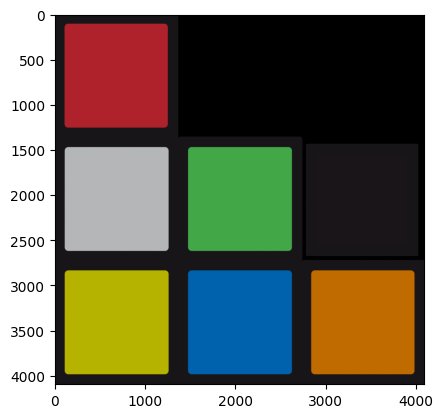

In [3]:
plt.imshow(texture)

In [4]:
# Grab the vertices and faces info from the mesh
uvs=np.asarray(mesh.triangle_uvs)
verts=np.asarray(mesh.vertices)
tris=np.asarray(mesh.triangles)



In [5]:
# mean subtract and normalize the positions

 # make sure the object fits inside our 1x1x1 box
verts[:,0]=verts[:,0]-np.mean(verts,axis=0)[0]
verts[:,1]=verts[:,1]-np.mean(verts,axis=0)[1]
verts[:,2]=verts[:,2]-np.mean(verts,axis=0)[2]

verts=verts/np.max(np.abs(verts))/4
verts[:,0]=verts[:,0] # move to the center of the box
verts[:,1]=verts[:,1] 
verts[:,2]=verts[:,2] 

In [6]:
theta = np.array([30,45,0]).astype(np.float32)*math.pi/180.0

RotMtxX = np.array([[1,0,0],
                    [0,math.cos(theta[0]),-math.sin(theta[0])],
                    [0,math.sin(theta[0]),math.cos(theta[0])]]) 
RotMtxY = np.array([[math.cos(theta[1]),0,math.sin(theta[1])],
                    [0,1,0],
                    [-math.sin(theta[1]),0,math.cos(theta[1])]]) 
RotMtxZ = np.array([[math.cos(theta[0]),-math.sin(theta[0]),0],
                    [math.sin(theta[0]),math.cos(theta[0]),0],
                    [0,0,1]]) 
R=RotMtxX@RotMtxY@RotMtxZ

In [7]:
h=1080; w=1080
img = 255*np.ones((h,w,3)).astype(np.uint8)

verts_rot=verts@R

verts2D = np.zeros((verts_rot.shape[0],2)).astype(verts_rot.dtype)
verts2D[:,0]=verts_rot[:,0]*w+w/2
verts2D[:,1]=verts_rot[:,1]*h+h/2

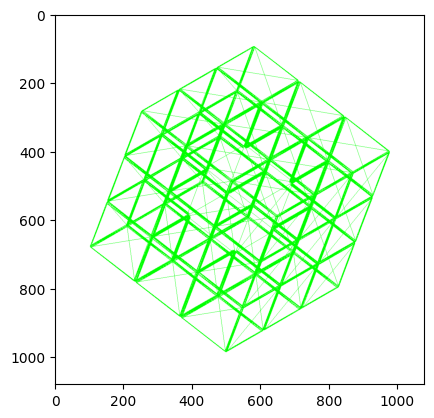

In [8]:

thickness=1
color=[0,255,0]
size=img.shape

for idx,tri in enumerate(tris):
    pts=verts2D[tri,:]
    
    pts3=np.int64(pts)
    cv2.line(img,pts3[0,:], pts3[1,:],color,thickness=thickness)
    cv2.line(img,pts3[1,:], pts3[2,:],color,thickness=thickness)
    cv2.line(img,pts3[2,:], pts3[0,:],color,thickness=thickness)

plt.imshow(img)

In [9]:
# Apply affine transform calculated using srcTri and dstTri to src and
# output an image of size.
def applyAffineTransform(src, srcTri, dstTri, size):

  # Given a pair of triangles, find the affine transform.
  warpMat = cv2.getAffineTransform(np.float32(srcTri), np.float32(dstTri))

  # Apply the Affine Transform just found to the src image
  dst = cv2.warpAffine(src, warpMat, (size[0], size[1]), None,
             flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)

  return dst

# Warps and alpha blends triangular regions from img1 and img2 to img
def warpTriangle(img1, img2, t1, t2):
  # Find bounding rectangle for each triangle
  r1 = cv2.boundingRect(np.float32([t1]))
  r2 = cv2.boundingRect(np.float32([t2]))

  # Offset points by left top corner of the respective rectangles
  t1Rect = []
  t2Rect = []
  t2RectInt = []

  for i in range(0, 3):
    t1Rect.append(((t1[i][0] - r1[0]), (t1[i][1] - r1[1])))
    t2Rect.append(((t2[i][0] - r2[0]), (t2[i][1] - r2[1])))
    t2RectInt.append(((t2[i][0] - r2[0]), (t2[i][1] - r2[1])))

  # Get mask by filling triangle
  mask = np.zeros((r2[3], r2[2], 3), dtype=np.float32)
  cv2.fillConvexPoly(mask, np.int32(t2RectInt), (1.0, 1.0, 1.0), 16, 0)

  # Apply warpImage to small rectangular patches
  img1Rect = img1[r1[1]:r1[1] + r1[3], r1[0]:r1[0] + r1[2]]

  size = (r2[2], r2[3])

  img2Rect = applyAffineTransform(img1Rect, t1Rect, t2Rect, size)

  img2Rect = img2Rect * mask

  # Copy triangular region of the rectangular patch to the output image
  img2[r2[1]:r2[1]+r2[3], r2[0]:r2[0]+r2[2]] = img2[r2[1]:r2[1]+r2[3], r2[0]:r2[0]+r2[2]] * ((1.0, 1.0, 1.0) - mask)
  img2[r2[1]:r2[1]+r2[3], r2[0]:r2[0]+r2[2]] = img2[r2[1]:r2[1]+r2[3], r2[0]:r2[0]+r2[2]] + img2Rect


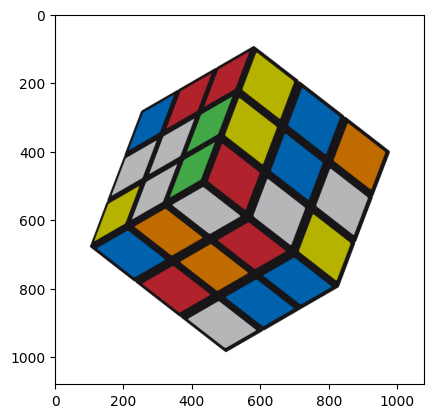

In [10]:
idxsort=np.argsort(np.max(verts_rot[tris,2],axis=1))

uv0=uvs[0::3]
uv1=uvs[1::3]
uv2=uvs[2::3]

tris=tris[idxsort,:]
uv0=uv0[idxsort,:]
uv1=uv1[idxsort,:]
uv2=uv2[idxsort,:]

img = 255*np.ones((h,w,3)).astype(np.uint8)

hp,wp,_=texture.shape
for idx,tri in enumerate(tris):
    pts=verts2D[tri,:]
    pts2=np.vstack((uv0[idx,:],uv1[idx,:],uv2[idx,:]))
    pts2[:,0]=pts2[:,0]*wp
    pts2[:,1]=pts2[:,1]*hp
    
    warpTriangle(texture, img, pts2, pts)

plt.imshow(img)